# Backtest by feature - sliding windows

Change the settings and **Run All**. Same entry / stop-loss rules as `window_analysis.ipynb`, run on **every window** of the data:

`WINDOW_SIZE = 30`, `STEP = 1` → candles **1-30, 2-31, 3-32, 4-33, ...** up to the last candle (change to 20, 25, 50, ... any time)

Two ways to run (`SYMBOLS`):
- **one symbol** - `'BTCUSDT'`: all 3 years of that symbol, every candle slides
- **all symbols** - `'ALL'`: every symbol in `data/`, all 3 years each, every candle slides (~40 s)

| file | what |
|---|---|
| `sliding.py` | sliding-window backtest: trades, per-window results, entire summary |
| `window.py` | one window in detail (section 4) |
| `tables.py` / `chart.py` / `theme.py` | styled tables, plotly figures, design |

A window owns the trades whose **entry signal is inside it** (a trade may close after the window ends) - same as `build_window`.

`OVERLAP = True`: every signal candle opens its own trade, so a window's result = sum of its signals' trades.
`OVERLAP = False`: one trade at a time, re-started at each window's first candle (signals while in a trade are skipped).

In [34]:
import importlib, sys
sys.path.insert(0, '..')              # project root: stop_loss.py, zone_create.py, data/
try:
    get_ipython().run_line_magic('autoreload', '0')   # autoreload off: it breaks on big module edits
except Exception:
    pass
import stop_loss, zone_create
import analysis.theme, analysis.window, analysis.sliding, analysis.tables, analysis.chart
for m in (stop_loss, zone_create, analysis.theme, analysis.window, analysis.sliding, analysis.tables, analysis.chart):
    importlib.reload(m)               # fresh code on every Run All - no kernel restart needed after editing .py files

from analysis.sliding import run_backtest, pick_window, all_symbols
from analysis.window import build_window
from analysis import tables, chart

# ---------------- what to backtest ----------------
SYMBOLS      = 'ALL'              # one symbol: 'BTCUSDT' | all symbols: 'ALL' | a list: ['BTCUSDT', 'ETHUSDT']
WINDOW_SIZE  = 30                     # candles per window: 20, 25, 30, 50, ...
STEP         = 1                      # candles between window starts: 1 -> 1-30, 2-31, 3-32 | 5 -> 1-30, 6-35, ...
PERIOD_START = None                   # None = first candle of the data (all 3 years) | e.g. '2025-01-01' (UTC)
PERIOD_END   = None                   # None = last candle | e.g. '2026-01-01' (not included)

# ---------------- features (same as window_analysis) ----------------
LEVERAGE    = 10                      # price % = position % / LEVERAGE
STOP_LOSS   = 0.10                    # initial stop, position % (0.10 = -10% -> 10x: -1% price)
TRAIL_STEP  = 0.10                    # trail starts once the trade reaches +TRAIL_STEP
TRAIL_GAP   = None                    # stop follows the best price this far behind (None = TRAIL_STEP); 0.05 locks more profit
TAKE_PROFIT = 0.50                    # exit at +50% position (10x -> +5% price)
MARGIN_USDT = 100                     # $ per trade for P&L
EMA_SET     = '13_48_200'             # '9_21_200' or '13_48_200' (never both)
SLOPE_MIN   = 0.05                    # fast EMA slope must be > this, ATR units (BUY > +min, SELL < -min)
OVERLAP     = True                    # True: trade every signal candle | False: one trade at a time
CLASSIFY    = True                    # precision / recall / f1: simulate a long + short from every candle (~11 s / symbol)

# ---------------- output ----------------
BREAKDOWN_SYMBOL = None               # sections 2-3: None = all symbols together | 'BTCUSDT'
SORT        = 'best'                  # window list order: None = time | 'best' | 'worst'
ROWS        = 20                      # rows in the window list
INSPECT     = 'best'                  # window to open in detail: 'best' | 'worst' | window number (1 = candles 1-WINDOW_SIZE)
INSPECT_SYMBOL = None                 # None = search all symbols | 'ETHUSDT' (needed for a window number with several symbols)
HIGHLIGHT   = 1                       # trade # drawn with full stop / TP detail (None = none)
SHOW_ZONES  = ['15m', '1h']           # add '4h', '1d'
ZOOM        = True
# ------------------------------------------

print('symbols in data/:', all_symbols())
print('Backtest is running......')
res = run_backtest(SYMBOLS, WINDOW_SIZE, STEP, PERIOD_START, PERIOD_END, LEVERAGE, OVERLAP, EMA_SET,
                   stop_loss=STOP_LOSS, trail_step=TRAIL_STEP, take_profit=TAKE_PROFIT, trail_gap=TRAIL_GAP,
                   slope_min=SLOPE_MIN, margin_usdt=MARGIN_USDT, classify=CLASSIFY)

symbols in data/: ['BNBUSDT', 'BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'XRPUSDT']
BNBUSDT: 311,603 candles | 84,341 trades | 311,574 windows
BTCUSDT: 311,603 candles | 83,254 trades | 311,574 windows
ETHUSDT: 311,603 candles | 80,949 trades | 311,574 windows
SOLUSDT: 311,603 candles | 85,247 trades | 311,574 windows
XRPUSDT: 311,603 candles | 79,954 trades | 311,574 windows


## 1. Entire summary

One column per symbol, plus **ALL** (every symbol together) when more than one.

**Top - period trades** (each trade counted once over the whole period): trades, win rate, total P&L $, avg win / loss,
profit factor (gross win / gross loss, > 1 = good), max drawdown of the cumulative P&L, exit reasons.

**Bottom - sliding windows** (every window `1-30, 2-31, ...`): `with trade %` = windows with at least one trade ·
`profitable %` / `losing %` = windows with net $ > 0 / < 0 · avg / median / best / worst net $ of one window ·
`window PF` = sum of winning windows $ / sum of losing windows $.
Windows overlap, so one trade sits in many windows - read these as "what a random window looks like", not as totals.

**Last block - entry quality** (`CLASSIFY = True`, details in section 3): precision / recall / f1 / accuracy of the entry signal, buy + sell together.

In [35]:
tables.bt_summary(res)

window 30 candles | step 1 | overlap (every signal trades) | margin 100$ / trade


,BNBUSDT,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT,ALL
metric,,,,,,
from,2023-12-05,2023-12-05,2023-12-05,2023-12-05,2023-12-05,2023-12-05
to,2026-11-20,2026-11-20,2026-11-20,2026-11-20,2026-11-20,2026-11-20
candles,"311,603","311,603","311,603","311,603","311,603","1,558,015"
trades,"84,341","83,254","80,949","85,247","79,954","413,745"
wins,"38,882","38,789","38,490","39,321","37,344","192,826"
losses,"45,459","44,465","42,459","45,926","42,610","220,919"
win rate,46.1%,46.6%,47.5%,46.1%,46.7%,46.6%
total P&L $,"-28,980.44","-55,126.86","-31,966.84","-72,440.10","-47,344.76","-235,859.00"
avg $ / trade,-0.34,-0.66,-0.39,-0.85,-0.59,-0.57


## 2. How entries make and lose money

Period trades (each counted once), `BREAKDOWN_SYMBOL` or all symbols together.
- **by side**: long vs short
- **by exit reason**: `stop` = initial stop hit (always a loss) · `trail` = trailing stop hit (win, or a small loss after fees) · `take_profit` = TP hit
- **by trade ROE**: how many trades end in each result band and how much $ each band adds or removes

`break-even win rate` = the win rate needed for net 0 with these average win / loss sizes.

In [36]:
tables.bt_breakdown(res, BREAKDOWN_SYMBOL)

BNBUSDT, BTCUSDT, ETHUSDT, SOLUSDT, XRPUSDT | 413,745 trades
  wins    192,826  avg  +10.31$  = gross profit +1,988,890.31$
  losses  220,919  avg  -10.07$  = gross loss   -2,224,749.32$
  net -235,859.00$ | win rate 46.6% | profit factor 0.89 | break-even win rate 49.4%


,trades,% of trades,wins,losses,win rate,avg win $,avg loss $,avg $,gross profit $,gross loss $,net $,profit factor,avg bars held,avg trail steps
long,"215,418",52.1%,"98,274","117,144",45.6%,+10.71,-10.04,-0.57,"+1,052,175.51","-1,175,543.40","-123,367.89",0.90,81.2,0.82
short,"198,327",47.9%,"94,552","103,775",47.7%,+9.91,-10.11,-0.57,"+936,714.81","-1,049,205.91","-112,491.11",0.89,67.8,0.80
all,"413,745",100.0%,"192,826","220,919",46.6%,+10.31,-10.07,-0.57,"+1,988,890.31","-2,224,749.32","-235,859.00",0.89,74.8,0.81


,trades,% of trades,wins,losses,win rate,avg win $,avg loss $,avg $,gross profit $,gross loss $,net $,profit factor,avg bars held,avg trail steps
stop (loss),"199,150",48.1%,0,"199,150",0.0%,-,-11.10,-11.10,+0.00,"-2,210,570.89","-2,210,570.89",0.00,63.4,0.00
trail (loss),"21,769",5.3%,0,"21,769",0.0%,-,-0.65,-0.65,+0.00,"-14,178.43","-14,178.43",0.00,74.4,1.00
trail (win),"188,061",45.5%,"188,061",0,100.0%,+9.34,-,+9.34,"+1,755,881.81",+0.00,"+1,755,881.81",inf,85.7,1.59
take_profit (win),"4,765",1.2%,"4,765",0,100.0%,+48.90,-,+48.90,"+233,008.50",+0.00,"+233,008.50",inf,118.6,3.28


,trades,% of trades,wins,losses,win rate,avg win $,avg loss $,avg $,gross profit $,gross loss $,net $,profit factor,avg bars held,avg trail steps
-15% to -10%,"199,150",48.1%,0,"199,150",0.0%,-,-11.10,-11.10,+0.00,"-2,210,570.89","-2,210,570.89",0.00,63.4,0.00
-10% to -5%,113,0.0%,0,113,0.0%,-,-6.80,-6.80,+0.00,-768.45,-768.45,0.00,27.2,1.00
-5% to +0%,"21,656",5.2%,0,"21,656",0.0%,-,-0.62,-0.62,+0.00,"-13,409.98","-13,409.98",0.00,74.7,1.00
+0% to +5%,"73,328",17.7%,"73,328",0,100.0%,+2.33,-,+2.33,"+170,723.10",+0.00,"+170,723.10",inf,74.7,1.00
+5% to +10%,"46,765",11.3%,"46,765",0,100.0%,+7.29,-,+7.29,"+341,107.65",+0.00,"+341,107.65",inf,87.2,1.19
+10% to +20%,"45,481",11.0%,"45,481",0,100.0%,+14.18,-,+14.18,"+644,741.76",+0.00,"+644,741.76",inf,93.4,2.08
+20% to +30%,"16,670",4.0%,"16,670",0,100.0%,+24.17,-,+24.17,"+402,917.18",+0.00,"+402,917.18",inf,101.6,3.09
+30% to +45%,"5,817",1.4%,"5,817",0,100.0%,+33.76,-,+33.76,"+196,392.12",+0.00,"+196,392.12",inf,107.0,4.00
> +45%,"4,765",1.2%,"4,765",0,100.0%,+48.90,-,+48.90,"+233,008.50",+0.00,"+233,008.50",inf,118.6,3.28


## 3. Entry quality - precision / recall / f1 / accuracy

The entry signal is scored as a classifier on **every candle** of the period (all signals, whatever `OVERLAP` is).
For each candle a long and a short are simulated with the same stop / trail / TP rules; **actual win** = that trade ends with ROE > 0 (after fees).

| | entry | no entry |
|---|---|---|
| **trade would win** | TP | FN (missed winner) |
| **trade would lose** | FP (bad entry) | TN (correctly skipped) |

- **precision** = TP / (TP + FP) = win rate of the entries
- **recall** = TP / (TP + FN) = share of all winning candles the entry catches
- **f1** = 2 · precision · recall / (precision + recall)
- **accuracy** = (TP + TN) / all · **specificity** = TN / (TN + FP) = share of losing candles correctly skipped
- **base rate** = win rate of a trade on a random candle · **lift** = precision / base rate (> 1 = the entry picks better than random)
- **avg $ entry** vs **avg $ any candle** = $ per trade with the entry filter vs trading every candle

BUY scores longs, SELL scores shorts, BOTH adds the two together.

In [37]:
tables.bt_classification(res, BREAKDOWN_SYMBOL)

BNBUSDT, BTCUSDT, ETHUSDT, SOLUSDT, XRPUSDT | 413,745 entries | precision 46.6% (random candle wins 44.9%, lift 1.04) | recall 13.8% | f1 21.3% | accuracy 54.2%


,BUY,SELL,BOTH
metric,,,
signals,"215,418","198,327","413,745"
"TP (entry, won)","98,274","94,552","192,826"
"FP (entry, lost)","117,144","103,775","220,919"
"FN (no entry, would win)","586,095","621,523","1,207,618"
"TN (no entry, would lose)","756,497","738,160","1,494,657"
precision,45.6%,47.7%,46.6%
recall,14.4%,13.2%,13.8%
f1,21.8%,20.7%,21.3%
accuracy,54.9%,53.4%,54.2%


## 4. Windows

`candles` = position in the period (1 = first candle). With several symbols the list covers all of them (`symbol` column).

In [38]:
tables.bt_windows(res, SORT, ROWS)

,symbol,window,candles,start_time,end_time,trades,wins,losses,win_rate,net_roe,net_$,best_roe,worst_roe
1,BNBUSDT,20835,20835-20864,2024-02-15 09:15,2024-02-15 11:40,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
2,BNBUSDT,20836,20836-20865,2024-02-15 09:20,2024-02-15 11:45,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
3,BNBUSDT,20837,20837-20866,2024-02-15 09:25,2024-02-15 11:50,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
4,BNBUSDT,20838,20838-20867,2024-02-15 09:30,2024-02-15 11:55,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
5,BNBUSDT,20839,20839-20868,2024-02-15 09:35,2024-02-15 12:00,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
6,BNBUSDT,20840,20840-20869,2024-02-15 09:40,2024-02-15 12:05,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
7,BNBUSDT,20841,20841-20870,2024-02-15 09:45,2024-02-15 12:10,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
8,BNBUSDT,28713,28713-28742,2024-03-13 17:45,2024-03-13 20:10,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
9,BNBUSDT,28714,28714-28743,2024-03-13 17:50,2024-03-13 20:15,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%
10,BNBUSDT,28715,28715-28744,2024-03-13 17:55,2024-03-13 20:20,30,30,0,100%,+1467.0%,"+1,467.00",+48.9%,+48.9%


## 5. Chart

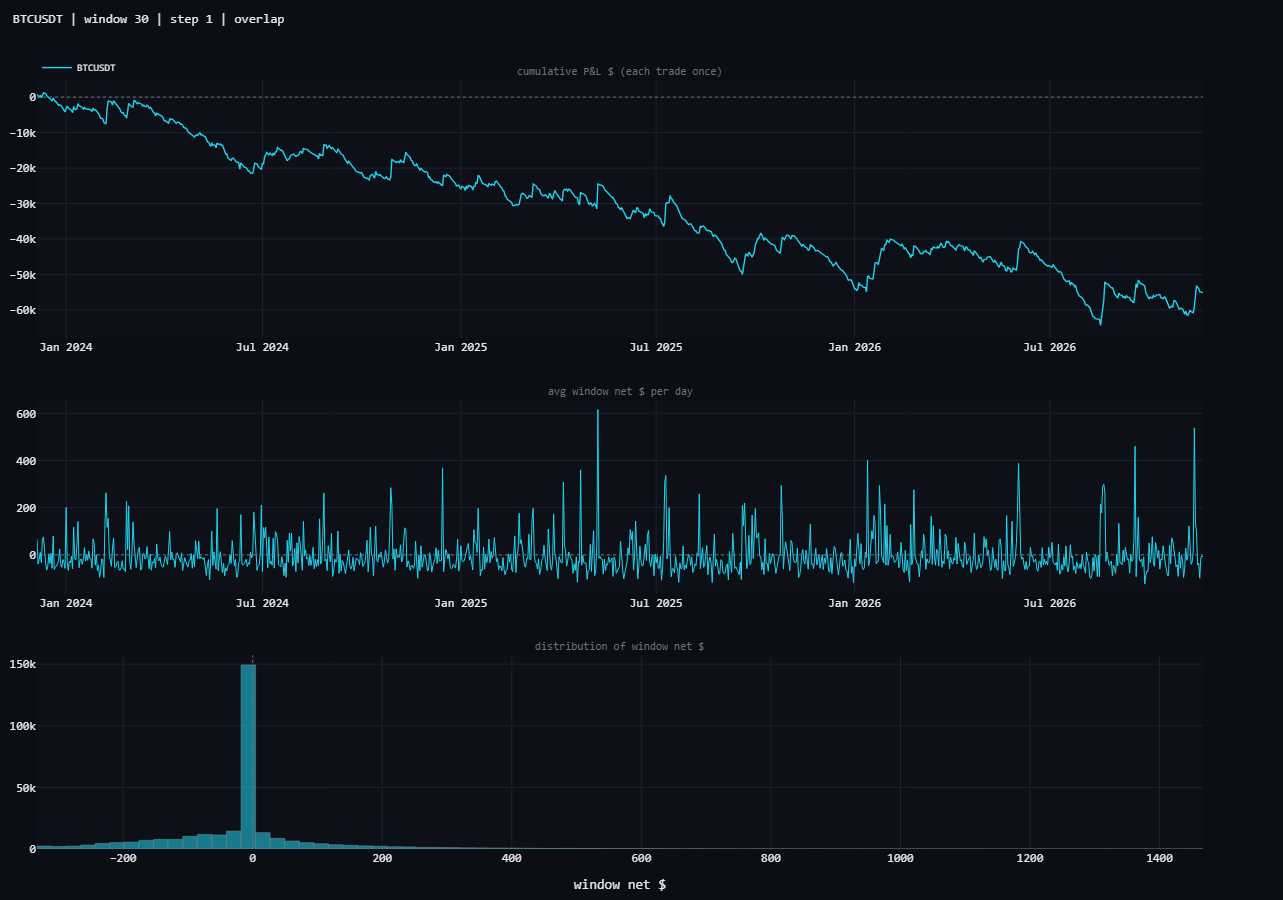

In [32]:
chart.plot_sliding(res).show()

## 6. Inspect one window

Opens the `INSPECT` window with `build_window` - same view as `window_analysis.ipynb`.

In [27]:
r = pick_window(res, INSPECT, INSPECT_SYMBOL)
print(f"{r.symbol} | window {r.window} | candles {r.candles} | {r.start_time} -> {r.end_time} | "
      f"{r.trades} trades | net {r['net_$']:+,.2f}$")
win = build_window(r.symbol, r.start_time.tz_localize(None), WINDOW_SIZE, LEVERAGE, OVERLAP, EMA_SET,
                   stop_loss=STOP_LOSS, trail_step=TRAIL_STEP, take_profit=TAKE_PROFIT, trail_gap=TRAIL_GAP, slope_min=SLOPE_MIN)
tables.trades(win, MARGIN_USDT)

BTCUSDT | window 149760 | candles 149760-149789 | 2025-05-08 01:00:00+00:00 -> 2025-05-08 03:25:00+00:00 | 30 trades | net +1,467.00$
30 trades | wins 30 | losses 0 | net +1,467.00$ | closed inside window 0, after window 30


,side,entry_time,entry,stop_init,take_profit,trail_steps,exit_time,exit,exit_reason,bars_held,roe,P&L $
1,long,2025-05-08 01:05:00+00:00,"97,976.42","96,996.66","102,875.24",4,2025-05-08 21:15:00+00:00,"102,875.24",take_profit,243,+48.9%,+48.90
2,long,2025-05-08 01:10:00+00:00,"97,960.37","96,980.76","102,858.39",4,2025-05-08 21:15:00+00:00,"102,858.39",take_profit,242,+48.9%,+48.90
3,long,2025-05-08 01:15:00+00:00,"97,857.14","96,878.57","102,750.00",4,2025-05-08 20:55:00+00:00,"102,750.00",take_profit,237,+48.9%,+48.90
4,long,2025-05-08 01:20:00+00:00,"97,804.32","96,826.28","102,694.54",4,2025-05-08 20:55:00+00:00,"102,694.54",take_profit,236,+48.9%,+48.90
5,long,2025-05-08 01:25:00+00:00,"97,976.19","96,996.43","102,875.00",4,2025-05-08 21:15:00+00:00,"102,875.00",take_profit,239,+48.9%,+48.90
6,long,2025-05-08 01:30:00+00:00,"97,982.52","97,002.70","102,881.65",4,2025-05-08 21:15:00+00:00,"102,881.65",take_profit,238,+48.9%,+48.90
7,long,2025-05-08 01:35:00+00:00,"97,963.53","96,983.90","102,861.71",4,2025-05-08 21:15:00+00:00,"102,861.71",take_profit,237,+48.9%,+48.90
8,long,2025-05-08 01:40:00+00:00,"97,958.01","96,978.43","102,855.91",4,2025-05-08 21:15:00+00:00,"102,855.91",take_profit,236,+48.9%,+48.90
9,long,2025-05-08 01:45:00+00:00,"97,831.18","96,852.87","102,722.74",4,2025-05-08 20:55:00+00:00,"102,722.74",take_profit,231,+48.9%,+48.90
10,long,2025-05-08 01:50:00+00:00,"97,803.76","96,825.72","102,693.95",4,2025-05-08 20:55:00+00:00,"102,693.95",take_profit,230,+48.9%,+48.90


In [28]:
tables.rules(win)

EMA test 13_48_200 | momentum: {'BULL': 30} | state: {'BUY': 30}


,time,open,high,low,close,EMA 13>48>200,EMA 200>48>13,EMA48 slope,EMA48 not flat,MOMENTUM,EMA13 slope,EMA13 slope ok,close-EMA13 (ATR),distance ok,Not touch EMA48,ENTRY,STATE
0,05-08 01:00,97770.00,98366.00,97756.61,97976.41,✔,✘,0.42,✔,BULL,0.36,✔,4.76,✔,✔,BUY,BUY
1,05-08 01:05,97976.42,98158.16,97895.34,97960.37,✔,✘,0.42,✔,BULL,0.36,✔,4.51,✔,✔,BUY,BUY
2,05-08 01:10,97960.37,97990.71,97752.95,97857.14,✔,✘,0.42,✔,BULL,0.36,✔,3.86,✔,✔,BUY,BUY
3,05-08 01:15,97857.14,97876.90,97600.00,97804.31,✔,✘,0.44,✔,BULL,0.33,✔,2.92,✔,✔,BUY,BUY
4,05-08 01:20,97804.32,98077.75,97804.31,97976.19,✔,✘,0.44,✔,BULL,0.33,✔,3.70,✔,✔,BUY,BUY
5,05-08 01:25,97976.19,98074.29,97933.52,97982.52,✔,✘,0.44,✔,BULL,0.33,✔,3.81,✔,✔,BUY,BUY
6,05-08 01:30,97982.52,98024.54,97849.59,97963.53,✔,✘,0.51,✔,BULL,0.33,✔,3.19,✔,✔,BUY,BUY
7,05-08 01:35,97963.53,98007.94,97953.95,97958.01,✔,✘,0.51,✔,BULL,0.33,✔,3.33,✔,✔,BUY,BUY
8,05-08 01:40,97958.01,97958.02,97800.00,97831.17,✔,✘,0.51,✔,BULL,0.33,✔,2.66,✔,✔,BUY,BUY
9,05-08 01:45,97831.18,97949.38,97736.33,97803.75,✔,✘,0.60,✔,BULL,0.22,✔,2.11,✔,✔,BUY,BUY


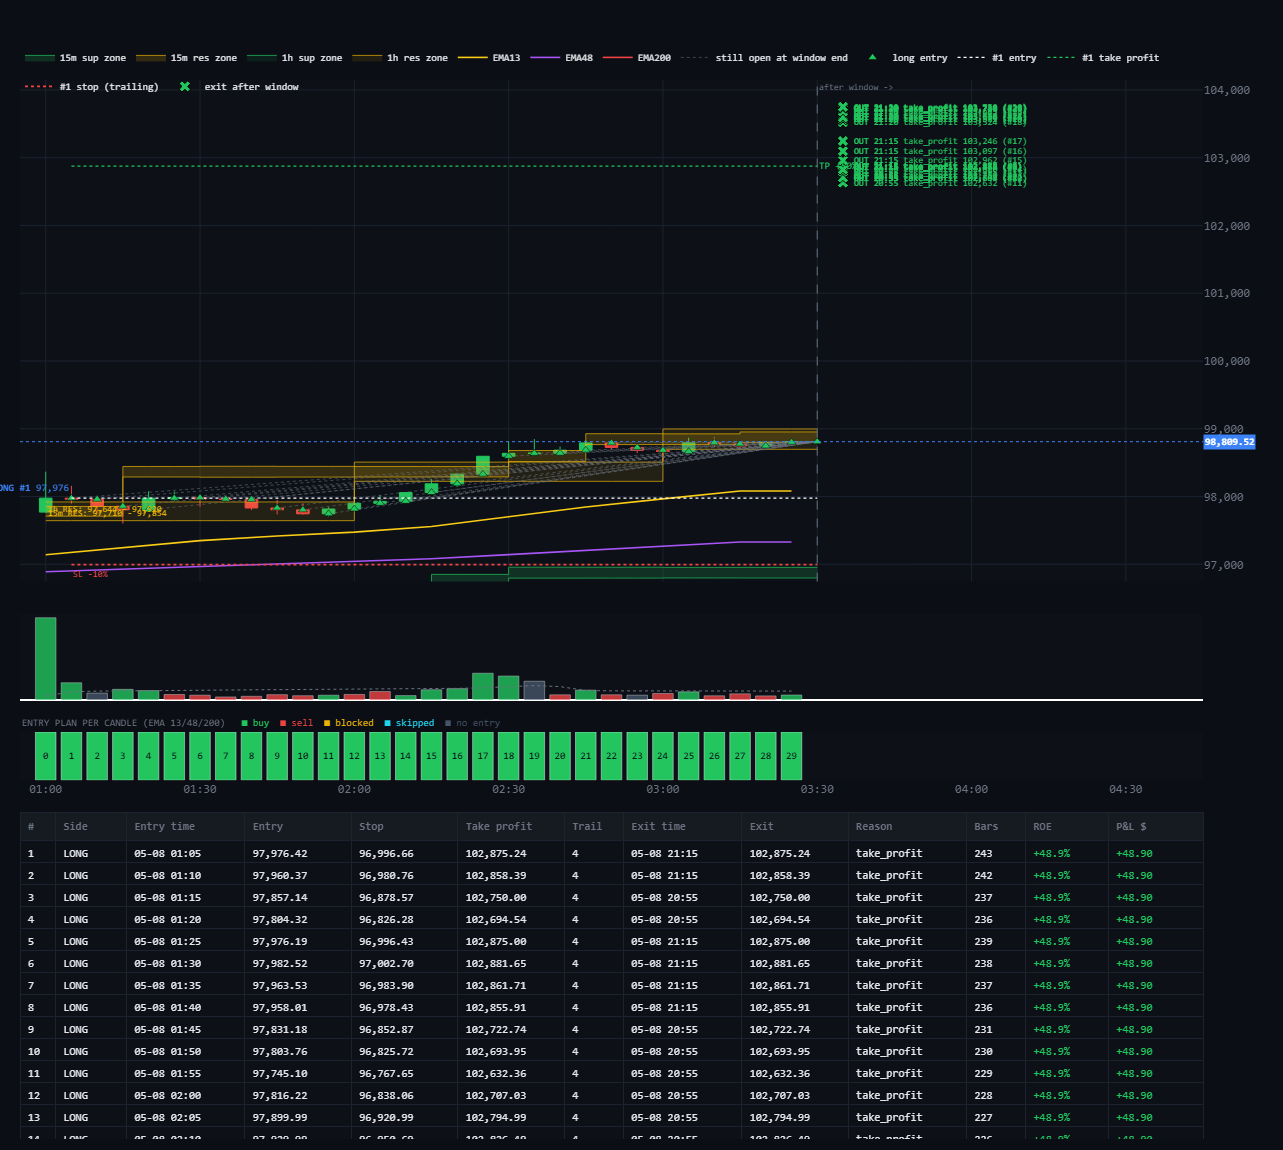

In [29]:
chart.plot_window(win, MARGIN_USDT, SHOW_ZONES, HIGHLIGHT, zoom=ZOOM).show()